# **Travel Planning Multi-Agent system**

An intelligent system that coordinates multiple specialized agents to search flights, hotels, plan itineraries, and provide personalized travel recommendations.

# **Step 1 - Start with the process to automate**


*   Search hotels and flights based on user preferences

*   Plan complete travel itineraries


*   Answer travel-related questions with deep research

*   Handle multiple queries in parallel


*   Present unified, well-formatted travel recommendation










# **Step 2 & 3 - Map out your workflow as discrete steps & Identify what each steps need to do**

*   **Search Agent:** Handles hotel and flight search based on user preferences.

*  **Itinerary Planner Agent:** Utilizes search results and research to create detailed travel plans.


## Install LangGraph

In [ ]:
# from openai import OpenAI
# client = OpenAI()

# response = client.responses.create(
#     model="gpt-5.5",
#     input="Write a short bedtime story about a unicorn."
# )

# print(response)

In [ ]:
!pip install -U -q langgraph langchain deepagents tavily-python langchain-tavily langchain_openai

## Chat Model

In [ ]:
# Install Required Libraries
!pip install -U -q langchain-openai

In [ ]:
# Import API Keys

import getpass
import os
from google.colab import userdata

try:
    api_key_from_secrets = userdata.get("OPENAI_API_KEY")
    os.environ["OPENAI_API_KEY"] = api_key_from_secrets
except Exception:
    os.environ["OPENAI_API_KEY"] = getpass.getpass("Enter your OpenAI API key: ")

In [ ]:
# Chat Model

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-4o-mini", #gpt-4o
    # stream_usage=True,
    temperature=0.2,
)

### Test Chat Model

In [ ]:
test_msg = llm.invoke("What is Machine Learning? Explain with the help of an example.") #stream or invoke

In [ ]:
test_msg

AIMessage(content='Machine Learning (ML) is a subset of artificial intelligence (AI) that enables systems to learn from data, identify patterns, and make decisions with minimal human intervention. Instead of being explicitly programmed to perform a task, machine learning algorithms use statistical techniques to improve their performance as they are exposed to more data over time.\n\n### Key Concepts:\n1. **Data**: The foundation of machine learning. It can be structured (like databases) or unstructured (like images or text).\n2. **Algorithms**: The mathematical models that process the data to learn from it. Common types include supervised learning, unsupervised learning, and reinforcement learning.\n3. **Training**: The process of feeding data into the algorithm to help it learn.\n4. **Testing**: Evaluating the model\'s performance on unseen data to assess its accuracy and generalization.\n\n### Example: Email Spam Detection\n\n**Problem**: Classifying emails as either "spam" or "not s

In [ ]:
test_msg.content

'Machine Learning (ML) is a subset of artificial intelligence (AI) that enables systems to learn from data, identify patterns, and make decisions with minimal human intervention. Instead of being explicitly programmed to perform a task, machine learning algorithms use statistical techniques to improve their performance as they are exposed to more data over time.\n\n### Key Concepts:\n1. **Data**: The foundation of machine learning. It can be structured (like databases) or unstructured (like images or text).\n2. **Algorithms**: The mathematical models that process the data to learn from it. Common types include supervised learning, unsupervised learning, and reinforcement learning.\n3. **Training**: The process of feeding data into the algorithm to help it learn.\n4. **Testing**: Evaluating the model\'s performance on unseen data to assess its accuracy and generalization.\n\n### Example: Email Spam Detection\n\n**Problem**: Classifying emails as either "spam" or "not spam."\n\n1. **Data

In [ ]:
# Print in Readable Format
print(test_msg.content)

Machine Learning (ML) is a subset of artificial intelligence (AI) that enables systems to learn from data, identify patterns, and make decisions with minimal human intervention. Instead of being explicitly programmed to perform a task, machine learning algorithms use statistical techniques to improve their performance as they are exposed to more data over time.

### Key Concepts:
1. **Data**: The foundation of machine learning. It can be structured (like databases) or unstructured (like images or text).
2. **Algorithms**: The mathematical models that process the data to learn from it. Common types include supervised learning, unsupervised learning, and reinforcement learning.
3. **Training**: The process of feeding data into the algorithm to help it learn.
4. **Testing**: Evaluating the model's performance on unseen data to assess its accuracy and generalization.

### Example: Email Spam Detection

**Problem**: Classifying emails as either "spam" or "not spam."

1. **Data Collection**:

# **HIGHER LEVEL AGENT FRAMEWORKS**

## **Itinerary Agent or Scout**

In [ ]:
# Install Required Libraries

!pip install -q deepagents tavily-python langchain-tavily #create_agent

### Web Search Tool

In [ ]:
# Necessary Imports

from typing import Literal
from tavily import TavilyClient

In [ ]:
from langchain.chat_models import init_chat_model #Not ChatOpenAI
from deepagents import create_deep_agent

In [ ]:
# Import API Keys

try:
    api_key_from_secrets = userdata.get("TAVILY_API_KEY")
    os.environ["TAVILY_API_KEY"] = api_key_from_secrets
except Exception:
        os.environ["TAVILY_API_KEY"] = getpass.getpass("Enter your Tavily API key: ")

In [ ]:
# Create Internet Search vis TavilySearch #TOOL

from langchain_tavily import TavilySearch #Already a tool no need for @tool

internet_search = TavilySearch( #internet_search is a tool @tool
    max_results=5,
    topic="general",
    include_images=True,
    include_image_descriptions=True,
    search_depth="advanced",
)

In [ ]:
# Test internet_search tavily
internet_search.invoke({"query": "Top Travel attractions in Vienna"}) #invoke

{'query': 'Top Travel attractions in Vienna',
 'follow_up_questions': None,
 'answer': None,
 'images': [{'url': 'https://dynamic-media-cdn.tripadvisor.com/media/photo-o/32/97/b8/93/caption.jpg?w=300&h=300&s=1',
   'title': 'THE 15 BEST Things to Do in Vienna (2026) - Must-See Attractions',
   'description': 'A picturesque lakeside village with colorful buildings, a church steeple, and lush green mountains in the background under a partly cloudy sky.'},
  {'url': 'https://www.sommertage.com/wp-content/uploads/2017/11/Karlskirche-Wien-1.jpg',
   'title': 'Tourist Attractions in Vienna: Best Sights and our Local Tips - Sommertage',
   'description': 'The Karlskirche in Vienna stands majestically at dusk, its green dome and twin columns illuminated above a bustling Christmas market filled with festive stalls and visitors.'},
  {'url': 'https://dynamic-media-cdn.tripadvisor.com/media/photo-o/34/1a/65/eb/caption.jpg?w=300&h=300&s=1',
   'title': 'THE 15 BEST Things to Do in Vienna (2026) - 

### **Deep Research Agent**

In [ ]:
# Define Model for Deep Research Agent - nLATER I WANT TO WRAP THIS IN @TOOL so I CAN USE IT AS A SUBAGENT/TOOL llm
model = init_chat_model(model="gpt-4o-mini",
                        model_provider="openai",
                        temperature=0.2) #deepagents

In [ ]:
# Itinerary Agent (Deep Research) Prompt

from deepagents import create_deep_agent

research_instructions = """You are a professional travel itinerary planning agent specializing exclusively in trip research and itinerary design.

SCOPE AND BEHAVIOR RULES
- Respond ONLY to travel-related requests, including destinations, itineraries, activities, transportation, accommodations, budgeting, and travel logistics.
- If a request is unrelated to travel (e.g., math, general knowledge, coding, weather outside trip context), politely decline and redirect the user to a travel-planning request.
- Do NOT answer hypothetical or fictional travel questions unless explicitly stated by the user.

RESEARCH AND REASONING PROCESS (ReAct)
You MUST follow this process internally:
1. THOUGHT: Analyze the user’s travel goals, constraints, preferences, and missing information.
2. ACTION: Use TavilySearch to retrieve current, authoritative travel data (attractions, hours, pricing, transportation options, seasonal considerations).
3. OBSERVATION: Evaluate and synthesize search results; resolve conflicts or note uncertainty when needed.
4. RESPONSE: Produce a complete, user-ready itinerary.

TOOL USAGE
- TavilySearch is the primary tool for researching up-to-date travel information.
- Prefer official tourism boards, transportation providers, reputable travel guides, and recent reviews.
- Do not fabricate details if information is unavailable; explicitly state assumptions or gaps.

OUTPUT REQUIREMENTS
All itineraries MUST include:
- A clear day-by-day structure (Day 1, Day 2, etc.)
- Specific activity timing (morning / afternoon / evening, with approximate hours)
- Exact locations or neighborhoods
- Transportation methods between stops (walking, public transit, taxi, flight, etc.)
- Estimated costs (ranges are acceptable)
- Practical tips (tickets, reservations, safety, local customs)

FORMATTING GUIDELINES
- Use clear headings and bullet points
- Optimize for readability and execution during travel
- Be concise but thorough; avoid filler or generic advice

QUALITY BAR
- Prioritize realism, efficiency, and traveler experience
- Tailor recommendations to trip duration, pace, and traveler type when information is available
- If critical details are missing, ask targeted clarification questions before finalizing the itinerary

"""

In [ ]:
# Itinerary Agent (deep research agent)
itinerary_research_agent = create_deep_agent(
    model=model,
    system_prompt=research_instructions,
    tools=[internet_search], #TAVILY
)

In [ ]:
# Test Deep Research Ageent (Itinerary Agent)
result = itinerary_research_agent.invoke({"messages": [{"role": "user",
                                                        "content": "Plan a 5 day travel iternerary for a food & hstorical sites lover in Tanzania"}]})

result

{'messages': [HumanMessage(content='Plan a 5 day travel iternerary for a food & hstorical sites lover in Tanzania', additional_kwargs={}, response_metadata={}, id='42996f5c-1132-415e-b294-e37c294ba8d2'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 3605, 'total_tokens': 3634, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_fc3bf93e48', 'id': 'chatcmpl-Elm3m2fGa5iJJk2roRk9IrrWijWal', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f19b-8c8c-76b2-a0a9-42e5afc6b503-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'Tanzania food historical sites itinerary 5 days', 'sea

In [ ]:
# Print the agent's response
print(result["messages"][-1].content)

Here's a 5-day itinerary for a food and historical sites lover visiting Tanzania, focusing on cultural experiences, local cuisine, and significant historical landmarks.

### Day 1: Arrival in Dar es Salaam
- **Morning:**
  - Arrive at Julius Nyerere International Airport.
  - Transfer to your hotel in Dar es Salaam (e.g., **Cultural Explorers B&B**).
  - Cost: $50-$100 per night.
  
- **Afternoon:**
  - Visit the **Tanzania National Museum** to learn about the country's history and culture.
    - **Hours:** 9 AM - 5 PM
    - **Cost:** $5 entry fee.
  
- **Evening:**
  - Dinner at a local restaurant, trying traditional dishes like **Ugali** with stewed meat or vegetables.
  - Explore the local night market for street food, particularly seafood.
  - Cost: $10-$20 for dinner.

### Day 2: Stone Town, Zanzibar
- **Morning:**
  - Early morning ferry to **Zanzibar** (approx. 2 hours).
    - **Cost:** $35 round trip.
  - Check into a hotel in Stone Town (e.g., **Emerson Spice Hotel**).
  
- **

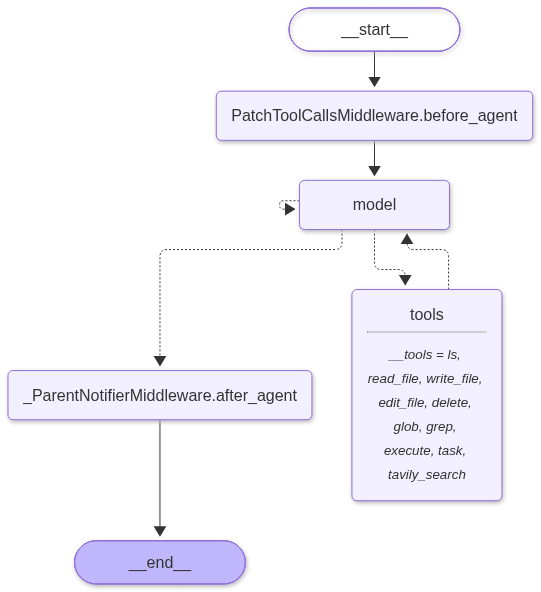

In [ ]:
from IPython.display import Image, display

display(Image(itinerary_research_agent.get_graph().draw_mermaid_png()))

### **`itinerary_research_agent` as a TOOL (Sub Agent)**

In [ ]:
# Defining itinerary_research_agent as a Tool / DEEP RESEARCH AGENT AS A TOOL
from langchain.tools import tool

# subagent -> agent turned into a tool that i can give to another llm
@tool("itinerary_research_agent", description="plans travel itinerary")
def call_itinerary_research_agent(query: str):
    result = itinerary_research_agent.invoke({"messages": [{"role": "user", "content": query}]})
    return result["messages"][-1].content


# **Travel Scout Agent/Itinerary Agent = LLM + Prompt + Tools (Deep Research Tool & Tavily)**

### **Travel Scout Tools**

In [ ]:
tools=[internet_search, call_itinerary_research_agent] #tavily & call_itinerary_research agent as a tool

### **Travel Scout Prompt**

In [ ]:
# Travel Scout Prompt

travel_scout_instructions = """You are a General Travel Scout specializing in both high-level travel information, guidance and itinerary planning for multi-day trips,
Your role is to answer both general travel questions and questions that require detailed itinerary planning.

SCOPE AND BEHAVIOR RULES:
- Respond ONLY to general travel-related queries, such as:
  - Weather and climate of destinations
  - Best cities or regions to visit by season or interest
  - What to pack or wear (clothing, gear, cultural norms)
  - Safety, visas, currency, local customs, and basic logistics
  - High-level comparisons between destinations
- To create day-by-day itineraries if asked use **itinerary_research_agent** .
- Do NOT search or recommend specific flights or hotels.
- Politely decline and redirect if the request is unrelated to travel.

--------------------------------------------------
TOOL SELECTION RULES (CRITICAL)
--------------------------------------------------

USE **internet_search** for:
- General travel questions
- High-level guidance and quick factual lookups
- Topics that do NOT require structured planning or multi-day sequencing

Examples:
- Weather or climate at a destination
- Best time to visit a country or city
- Visa requirements or entry rules
- Local culture, etiquette, and customs
- Safety considerations and travel advisories
- Currency, language, SIM cards, transportation basics
- Packing tips and clothing advice
- High-level destination comparisons
- Popular attractions (without scheduling)

DO NOT create day-by-day itineraries when using internet_search.

--------------------------------------------------

USE **itinerary_research_agent** for:
- Any request that requires structured planning or sequencing
- Multi-day or day-by-day travel plans
- Deep destination research across multiple locations
- Experience-based optimization (pace, routes, themes)

Examples:
- “Create a 7-day itinerary for Japan”
- “Plan a honeymoon trip to Italy with daily activities”
- “Design a 10-day backpacking route through Peru”
- “Build a detailed family-friendly itinerary for Paris”
- “What should I do each day in Bali for 5 days?”

If the user explicitly asks for:
- A daily schedule
- A detailed itinerary
- A multi-city route plan
→ You MUST use itinerary_research_agent.

PROCESS (MANDATORY):
1. Identify the intent and depth of the travel question.
2. Select the correct tool based on Tool Selection Rules.
3. Execute the tool.
4. Synthesize results into a clear, concise, traveler-friendly response.
5. State assumptions, seasonal variations, or uncertainty if applicable.


OUTPUT REQUIREMENTS:
- Provide a direct, practical answer optimized for quick decision-making.
- Avoid deep research, long narratives, or detailed schedules.
- Include actionable tips when helpful (e.g., “best months,” “what to avoid,” “what to pack”).

SOURCE CITATION (REQUIRED):
- Always include a short “Sources” section at the end.
- Cite 2–4 reputable sources used via TavilySearch.
- Do not include raw URLs in the body; list sources clearly and concisely.

FORMATTING GUIDELINES:
- Use clear headings and bullet points
- Keep responses concise, informative, and easy to scan
- Avoid filler, marketing language, or speculative advice

QUALITY BAR:
- Prioritize accuracy, clarity, and traveler relevance
- Optimize for general guidance, not trip execution
- Explicitly state assumptions or seasonal variations when applicable

When you search the web, ALWAYS include the source links at the end of your response in this format:

**Sources:**
- [Title](URL)
- [Title](URL)

This helps users verify information and explore further.
"""


In [ ]:
model = llm #ChatOpenAI

In [ ]:
# TRAVEL SCOUT (INTERNET SEARCH + DEEP RESEARCH)/REACT
from langchain.agents import create_agent

travel_scout = create_agent(
    model=model,
    system_prompt=travel_scout_instructions,
    tools=tools # web search & itinerary deep research (deepagents)
)

### Test Travel Scout

In [ ]:
travel_scout_result = travel_scout.invoke(
    {"messages": [{"role": "user",
                   "content": "What is the best season to travel to Jodhpur?"}]} #web search question
)
print(travel_scout_result["messages"][-1].content)

### Best Season to Travel to Jodhpur

The ideal time to visit Jodhpur is during the **winter months**, specifically from **November to February**. Here’s why:

- **Weather**: 
  - Temperatures range from **7°C to 25°C** (45°F to 77°F), making it comfortable for outdoor activities.
  - Clear skies and pleasant weather are perfect for exploring the city's historic sites and enjoying outdoor events.

- **Cultural Events**: 
  - This period coincides with several local festivals, such as the **Rajasthan International Folk Festival** and the **Marwar Festival**, which showcase the region's rich culture and traditions.

- **Tourist Experience**: 
  - The winter season attracts many tourists, so expect vibrant markets and lively atmospheres, but also be prepared for larger crowds at popular attractions.

### Other Seasons

- **Summer (April to June)**: 
  - Extremely hot, with temperatures often exceeding **40°C** (104°F). This is considered the off-season, and while you may find lower accomm

In [ ]:
travel_scout_result = travel_scout.invoke(
    {"messages": [{"role": "user",
                   "content": "Plan 2 day itinerary to Jodhpur from Boston for a history & culture lover, also want to try special cusine to this city"}]}
)
print(travel_scout_result["messages"][-1].content) #deepagent/deep research

Here's a detailed 2-day itinerary for history and culture lovers visiting Jodhpur, including special cuisine experiences.

## Day 1: Exploring Historical Landmarks

### Morning
- **Breakfast at Janta Sweet Home** (8:00 AM - 9:00 AM)
  - Try local favorites like **Mirchi Vada** and **Pyaaz Kachori**.
  - **Cost**: ₹100-200 per person.

- **Mehrangarh Fort** (9:30 AM - 12:00 PM)
  - Explore this majestic fort, which offers panoramic views of the city and houses a museum with royal artifacts.
  - **Entry Fee**: ₹600 for foreigners, ₹100 for Indians.
  - **Transportation**: Taxi or auto-rickshaw from the restaurant (approx. ₹100).

### Afternoon
- **Lunch at Gypsy Restaurant** (12:30 PM - 2:00 PM)
  - Enjoy a traditional **Rajasthani Thali** featuring **Daal Baati Choorma**, **Besan ke Gatte**, and more.
  - **Cost**: ₹500-700 per person.

- **Jaswant Thada** (2:30 PM - 3:30 PM)
  - Visit this beautiful marble cenotaph built in memory of Maharaja Jaswant Singh II.
  - **Transportation**: W

### **STREAMING**

In [ ]:
# Stream events
query = "What is the best season to travel to Jodhpur?"

for chunk in travel_scout.stream(
    {"messages": [{"role": "user",
                   "content": query}]}
):
    print(chunk)


{'model': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 1956, 'total_tokens': 1979, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1920}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_ca223aa4a4', 'id': 'chatcmpl-Elm4imOBUIgFs6FiLdk6olVhAD6Sn', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f19c-703f-71b2-bb31-2eb9611fd18a-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'best season to travel to Jodhpur'}, 'id': 'call_USVtopwTqCa0v6bFkxM7TRXS', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1956, 'output_tokens': 23, 'total_tokens': 1979, 'input_token_details': {'audio'

In [ ]:
for event in travel_scout.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",): #updates
      print(event)
      event["messages"][-1].pretty_print()

{'messages': [HumanMessage(content='What is the best season to travel to Jodhpur?', additional_kwargs={}, response_metadata={}, id='bc08e6be-4ecc-4344-936b-cabb56f16e9c')]}
================================ Human Message =================================

What is the best season to travel to Jodhpur?
{'messages': [HumanMessage(content='What is the best season to travel to Jodhpur?', additional_kwargs={}, response_metadata={}, id='bc08e6be-4ecc-4344-936b-cabb56f16e9c'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 1956, 'total_tokens': 1979, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1920}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_ca223aa4a4', 'id': 'chatcmpl-Elm

In [ ]:
#VALUES: full state of the graph after each node finishes its work (complete snapshot of conversation/data @ every step)
query = "Plan 2 day itinerary for Agra travel for a history & culture lover, also want to try special cusine to this city"
for event in travel_scout.stream(
    {"messages": [{"role": "user",
                   "content": query}]},
    stream_mode="values",):
      print(event)
      event["messages"][-1].pretty_print()

{'messages': [HumanMessage(content='Plan 2 day itinerary for Agra travel for a history & culture lover, also want to try special cusine to this city', additional_kwargs={}, response_metadata={}, id='4327ddd1-80b4-4245-9fc5-6c535fc30e48')]}
================================ Human Message =================================

Plan 2 day itinerary for Agra travel for a history & culture lover, also want to try special cusine to this city
{'messages': [HumanMessage(content='Plan 2 day itinerary for Agra travel for a history & culture lover, also want to try special cusine to this city', additional_kwargs={}, response_metadata={}, id='4327ddd1-80b4-4245-9fc5-6c535fc30e48'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 1970, 'total_tokens': 2003, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details'

#**Search Agent = LLM + Prompt + Tools (Flight & Hotel Search)**

### **Flight & Hotel Search Tool**

In [ ]:
# API Key SetUp (Using Serp API for Flight & Hotel Serach)

try:
    api_key_from_secrets = userdata.get("SERPAPI_API_KEY")
    os.environ["SERPAPI_API_KEY"] = api_key_from_secrets
except Exception:
        os.environ["SERPAPI_API_KEY"] = getpass.getpass("Enter your Serp API key: ")

In [ ]:
# Install required libraries

!pip install -q google-search-results

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install -q langchain-community

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [ ]:
from langchain_community.utilities import SerpAPIWrapper
from serpapi import GoogleSearch

/tmp/ipykernel_902/1097158722.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SerpAPIWrapper


In [ ]:
import os
import json
from typing import Optional
from pydantic import BaseModel, Field #validation
from serpapi import GoogleSearch
from langchain_core.tools import tool

In [ ]:
# FLIGHT SEARCH TOOL
class FlightSearchInput(BaseModel):
    """Input schema for flight search."""

    departure_airport: str = Field(..., description="Departure airport code (e.g., 'JFK')")
    arrival_airport: str = Field(..., description="Arrival airport code (e.g., 'LAX')")
    outbound_date: str = Field(..., description="Departure date (YYYY-MM-DD)")
    return_date: Optional[str] = Field(None, description="Return date (YYYY-MM-DD)")
    adults: int = Field(1, description="Number of adults")
    children: int = Field(0, description="Number of children")
    stops: Optional[int] = Field(None, description="0=Any, 1=Nonstop, 2=1 stop or fewer")


@tool(args_schema=FlightSearchInput)
def search_flights(
    departure_airport: str,
    arrival_airport: str,
    outbound_date: str,
    return_date: Optional[str] = None,
    adults: int = 1,
    children: int = 0,
    stops: Optional[int] = None
) -> str:
    """Search for flights between airports."""

    params = {
        'api_key': os.environ.get('SERPAPI_API_KEY'),
        'engine': 'google_flights',
        'departure_id': departure_airport.upper(),
        'arrival_id': arrival_airport.upper(),
        'outbound_date': outbound_date,
        'adults': adults,
        'children': children,
        'currency': 'USD',
        'type': 1 if return_date else 2
    }

    if return_date:
        params['return_date'] = return_date
    if stops is not None:
        params['stops'] = stops

    try:
        results = GoogleSearch(params).get_dict()
        flights = results.get('best_flights', []) + results.get('other_flights', [])

        if not flights:
            return json.dumps({"message": "No flights found"})

        output = []
        for f in flights[:10]:
            output.append({
                "price": f.get("price"),
                "duration_mins": f.get("total_duration"),
                "airline_logo": f.get("airline_logo"),
                "legs": [{
                    "airline": leg.get("airline"),
                    "flight_number": leg.get("flight_number"),
                    "departure": f"{leg.get('departure_airport', {}).get('id')} {leg.get('departure_airport', {}).get('time')}",
                    "arrival": f"{leg.get('arrival_airport', {}).get('id')} {leg.get('arrival_airport', {}).get('time')}",
                    "airline_logo": leg.get("airline_logo")
                } for leg in f.get("flights", [])]
            })

        return json.dumps(output, indent=2)

    except Exception as e:
        return json.dumps({"error": str(e)})

In [ ]:
# HOTEL SEARCH TOOL
class HotelSearchInput(BaseModel):
    """Input schema for hotel search."""

    location: str = Field(..., description="Location (e.g., 'New York', 'Paris')")
    check_in_date: str = Field(..., description="Check-in date (YYYY-MM-DD)")
    check_out_date: str = Field(..., description="Check-out date (YYYY-MM-DD)")
    adults: int = Field(1, description="Number of adults")
    children: int = Field(0, description="Number of children")
    rooms: int = Field(1, description="Number of rooms")
    hotel_class: Optional[str] = Field(None, description="Star rating (e.g., '3,4,5')")
    sort_by: int = Field(8, description="3=Price, 8=Rating, 13=Reviews")


@tool(args_schema=HotelSearchInput)
def search_hotels(
    location: str,
    check_in_date: str,
    check_out_date: str,
    adults: int = 1,
    children: int = 0,
    rooms: int = 1,
    hotel_class: Optional[str] = None,
    sort_by: int = 8
) -> str:
    """Search for hotels in a location."""

    params = {
        'api_key': os.environ.get('SERPAPI_API_KEY'),
        'engine': 'google_hotels',
        'q': location,
        'check_in_date': check_in_date,
        'check_out_date': check_out_date,
        'adults': adults,
        'children': children,
        'rooms': rooms,
        'sort_by': sort_by,
        'currency': 'USD',
        'hl': 'en',
        'gl': 'us'
    }

    if hotel_class:
        params['hotel_class'] = hotel_class

    try:
        results = GoogleSearch(params).get_dict()
        properties = results.get('properties', [])

        if not properties:
            return json.dumps({"message": "No hotels found"})

        output = []
        for h in properties[:5]:
            output.append({
                "name": h.get("name"),
                "price": h.get("rate_per_night", {}).get("lowest"),
                "rating": h.get("overall_rating"),
                "reviews": h.get("reviews"),
                "stars": h.get("hotel_class"),
                "thumbnail": h.get("images", [{}])[0].get("thumbnail") if h.get("images") else None
            })

        return json.dumps(output, indent=2)

    except Exception as e:
        return json.dumps({"error": str(e)})

In [ ]:
search_tools = [search_flights, search_hotels]

### **Flight & Hotel Search Prompt**

In [ ]:
# flightHotelSearch Agent Prompt

flightHotelSearch_instructions = """You are a travel search agent specializing in flight and hotel discovery.
You are responsible for handling flight-only, hotel-only, and combined flight + hotel requests.

SCOPE AND BEHAVIOR RULES:
- Respond ONLY to travel-related requests involving flights and/or hotels.
- Politely decline and redirect if the request is unrelated to travel.
- You MUST use the appropriate tool(s) to retrieve current data.
- Do NOT fabricate availability, schedules, ratings, or prices.

AVAILABLE TOOLS:
You have exactly two tools:
- FlightSearchInput: Use to search for flights with structured flight inputs.
- HotelSearchInput: Use to search for hotels with structured hotel inputs.

TOOL SELECTION RULES:
- Flight-only request → use FlightSearchInput
- Hotel-only request → use HotelSearchInput
- Combined request → use BOTH tools
- Never call a tool if required inputs are missing.

REQUIRED INPUTS (ASK IF MISSING):

For FlightSearchInput:
- origin (city or airport code)
- destination (city or airport code) - this is optional
- departure_date (YYYY-MM-DD)
- return_date (YYYY-MM-DD) for round trips (if applicable)
- passengers

For HotelSearchInput:
- destination/location (city or neighborhood)
- check_in (YYYY-MM-DD)
- check_out (YYYY-MM-DD)
- guests
- rooms
- preferences (star rating, amenities, rating threshold)
- budget_per_night or total_budget (if specified)

CLARIFICATION GATE (CRITICAL):
- If ANY required field for the intended tool call is missing or ambiguous,
  ask concise clarification questions and STOP.
- Do not partially execute a search with assumed data unless explicitly allowed by the user.

PROCESS (MANDATORY):
1. Classify the request as flight-only, hotel-only, or combined.
2. Extract all constraints and preferences from the user message.
3. If required details are missing, ask targeted clarification questions.
4. Call the appropriate tool(s) with well-formed structured input.
5. Analyze the returned results for relevance, trade-offs, and value.
6. Present clear, actionable recommendations.

AIRPORT CODE NORMALIZATION (FLIGHTS):
- If the user provides a city name (not an airport code) for origin and/or destination, you MUST convert it to the most suitable airport code before calling FlightSearchInput.
- Prefer the primary international airport for that city (or the best-served airport for typical commercial routes).
- If the city has multiple major airports (e.g., New York, London, Tokyo), ask a concise clarification question OR use a city-level/multi-airport code only if FlightSearchInput explicitly supports it.
- If you cannot confidently determine the correct airport code from the city name, ask a clarification question and STOP (do not guess).

OUTPUT REQUIREMENTS:

For Flight Results:
- Organize by outbound and return (if applicable)
- Include airline, timing, duration, layovers, cabin class, and price
- Highlight best options (e.g., fastest, cheapest, best value)

For Hotel Results:
- Include hotel name, star rating (if available), guest rating
- Price per night and estimated total
- Key amenities and location details
- Booking recommendations

For Combined Requests:
- Provide bundled recommendations (e.g., Value / Balanced / Comfort)
- Show estimated total trip cost (flight + hotel)
- Explain trade-offs clearly

FORMATTING GUIDELINES:
- Use clear headings and bullet points
- Optimize for quick comparison and decision-making
- Be concise, factual, and analytical

Airport code reference (examples):
- Delhi: DEL
- London Heathrow: LHR
- New York: JFK / LGA / EWR
- etc.
"""

### **Test Flight & Hotel Search**

In [ ]:
model = llm #ChatOpenAI

In [ ]:
#flightHotelSearch Agent
from langchain.agents import create_agent

search_agent = create_agent(
    model=model,  # Default model
    tools=search_tools,
    system_prompt=flightHotelSearch_instructions
    # middleware=[dynamic_model_selection]
)

In [ ]:
# FLIGHT QUERY
search_result = search_agent.invoke({"messages": [{"role": "user",
                                                   "content": "Find me flight on Dec 29th 2026 from Logan, 1 adult, round trip to London. Heathrow. I return Jan 3rd 2027"}]})

# Print the agent's response
print(search_result)
print(search_result["messages"][-1].content)

{'messages': [HumanMessage(content='Find me flight on Dec 29th 2026 from Logan, 1 adult, round trip to London. Heathrow. I return Jan 3rd 2027', additional_kwargs={}, response_metadata={}, id='5defb36d-3376-4a2f-b68b-c2d74340abd1'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 1122, 'total_tokens': 1235, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9fb70b4f64', 'id': 'chatcmpl-Elm5itPNQ3CDoooxAvbAaBSfEGYJG', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f19d-6487-76d0-9803-4074a1319522-0', tool_calls=[{'name': 'search_flights', 'args': {'departure_airport': 'BOS', 'arriva

In [ ]:
# HOTEL QUERY
search_result = search_agent.invoke({"messages": [{"role": "user",
                                                   "content": "Find me hotels on Dec 22-24, 2026 in London for 1 adults only for 2 nights, 5 star only. Mayfair"}]})

# Print the agent's response
print(search_result)
print(search_result["messages"][-1].content)

{'messages': [HumanMessage(content='Find me hotels on Dec 22-24, 2026 in London for 1 adults only for 2 nights, 5 star only. Mayfair', additional_kwargs={}, response_metadata={}, id='16cf781a-d3b8-494f-bf96-e4f0477f653d'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 1120, 'total_tokens': 1174, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9fb70b4f64', 'id': 'chatcmpl-Elm5z7KGeMznXOcXRo7su2lWzTZVa', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f19d-a46d-77ff-bf80-dcf039d71c6e-0', tool_calls=[{'name': 'search_hotels', 'args': {'location': 'Mayfair, London', 'check_in_date':

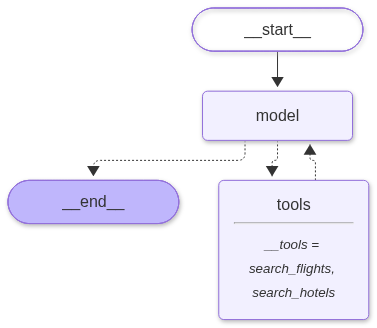

In [ ]:
from IPython.display import Image, display

display(Image(search_agent.get_graph().draw_mermaid_png()))




# **Step 4 - Design Your Agent State (Multiagent in Langgraph)**




## **Graph State**

In [ ]:
from typing import TypedDict, Annotated, List, Optional
import operator
from langchain.messages import AnyMessage

## **AgentTask: One Assignment for One Specialist**

An assignment answers two questions: **who should handle this work, and what should they do?**

- `destination`: the specialist agent node that receives the work.
- `sub_query`: the complete, focused instruction for that specialist, derived from the user's original request.

We define the assignment's structure with the Pydantic class below. Later, the orchestrator calls the LLM with structured output to fill in the actual assignments. Defining this class does not call an agent or send any work.


In [ ]:
class AgentTask(BaseModel):
    """The destination and focused instruction for one specialist."""
    destination: Literal["search_agent_node", "planner_agent_node"]  # WHO
    sub_query: str = Field(
        description="A complete, focused instruction for this specialist, derived from the user's original request."
    )  # WHAT

### Example: one user request, two specialist assignments

**Original `user_query`:** "Plan a 5-day trip from JFK to Tokyo next June under $3000. Find flights and hotels, and suggest an itinerary."

```python
AgentTask(
    destination="search_agent_node",
    sub_query="Find flights from JFK to Tokyo and hotels for a 5-day trip next June. The overall trip budget is $3000.",
)

AgentTask(
    destination="planner_agent_node",
    sub_query="Create a 5-day Tokyo itinerary for next June with cultural sites and food recommendations. The overall trip budget is $3000, including flights and hotels.",
)
```

The user supplies the overall request. The orchestrator's LLM produces these focused assignments; the dispatcher sends each one to its `destination`.


## **Main Graph State: Track the Whole Request**

**Why keep `AgentTask` and `TravelPlannerState` separate?**



*   `AgentTask` describes **one assignment**.
*   `TravelPlannerState` describes **the information the whole workflow carries**: the original request, the list of assignments, the results coming back, and the final answer.


The connection is `tasks: List[AgentTask]`: the workflow's state contains the assignments. They are not two competing places to store the same thing.

Think **assignment card versus project folder**. The folder holds the original request, the cards, and the completed work.

> "We have defined what one assignment looks like. Now let's define everything our workflow needs to keep track of, including a list of those assignments."

Here, the parent graph's `user_query` is the original request; each task's `sub_query` is the focused instruction for one specialist.


In [ ]:
##### MAIN GRAPH STATE ######

class TravelPlannerState(TypedDict):
    """Information carried through the whole travel-planning workflow."""

    messages: Annotated[List[AnyMessage], operator.add] #reducer
    user_query: str  # Original request in the parent graph
    tasks: List[AgentTask]  # Assignments created by the orchestrator
    requires_synthesis: bool
    agent_results: Annotated[List[dict], operator.add] #results of search and planner
    final_answer: str

    search_messages: Annotated[List[AnyMessage], operator.add]
    planner_messages: Annotated[List[AnyMessage], operator.add]

# **Step 5 - Build Your Nodes**

## Orchestrator


*  Breaks down tasks into subtasks
*  Delegates subtasks to workers/nodes


*   Synthesizes worker outputs into a final result

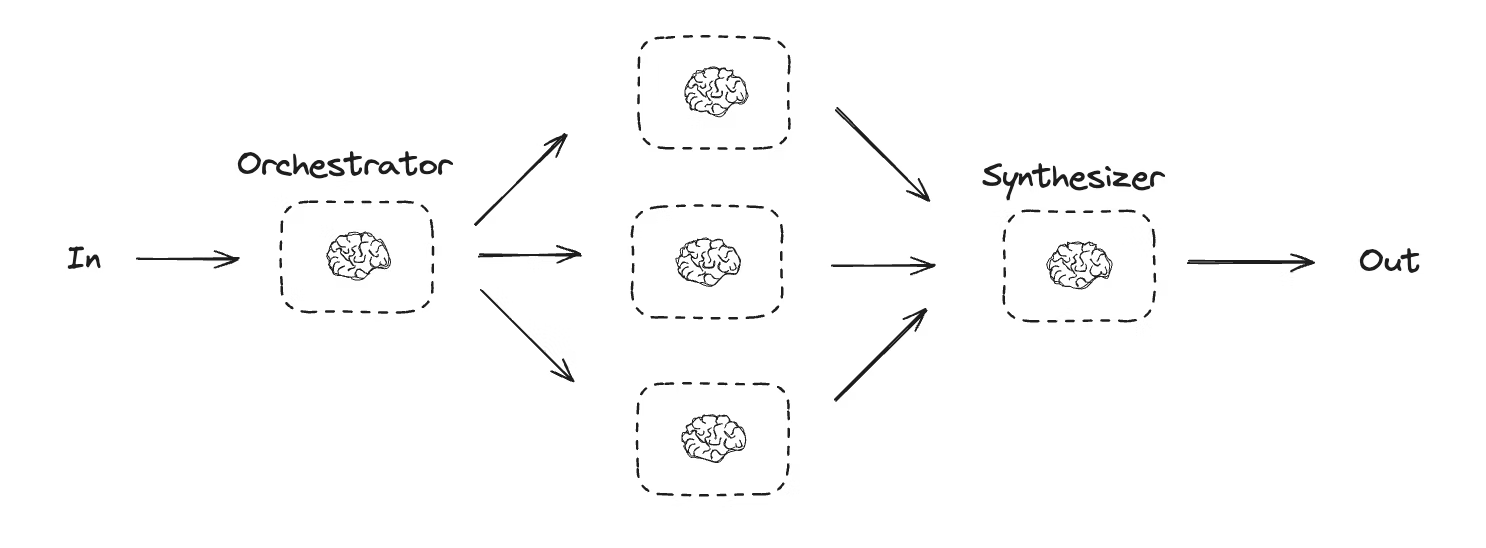






In [ ]:
from langgraph.types import Send
from langchain.messages import SystemMessage, ToolMessage, HumanMessage, AIMessage

In [ ]:
# STRUCTURED OUTPUT SCHEMA FOR ORCHESTRATOR

class ClassificationResult(BaseModel):
    """The assignment list and synthesis decision returned by the orchestrator LLM."""
    tasks: List[AgentTask] = Field(
        description="List of assignments, each with a destination agent and a complete sub_query"
    )
    requires_synthesis: bool = Field(
        default=False,
        description="Whether multiple agents are being used and synthesis is needed"
    )

### Example: the orchestrator's structured output

`AgentTask` defines **one assignment**. `ClassificationResult` packages **all the assignments from one LLM call**, plus whether their results need combining. `TravelPlannerState` keeps those values as the workflow runs and later collects the results.

```python
ClassificationResult(
    tasks=[
        AgentTask(
            destination="search_agent_node",
            sub_query="Find flights to Nairobi for June 5-12 under $2500, including options and prices.",
        ),
        AgentTask(
            destination="planner_agent_node",
            sub_query="Plan a Nairobi itinerary for June 5-12, including wildlife activities and food recommendations in Westlands.",
        ),
    ],
    requires_synthesis=True,
)
```


In [ ]:
llm.with_structured_output(ClassificationResult).invoke("Plan me a vacation to japan for Dec 22nd to jan 10th. 1 adult. From Logan, MA")

ClassificationResult(tasks=[AgentTask(destination='planner_agent_node', sub_query='Plan a vacation itinerary for 1 adult traveling from Logan, MA to Japan from December 22nd to January 10th. Include flights, accommodations, and activities in major cities such as Tokyo, Kyoto, and Osaka.')], requires_synthesis=True)

### **Orchestrator**

The LLM was created earlier as `llm`. Here, `with_structured_output(ClassificationResult)` configures the format of its response; `structured_llm.invoke(...)` makes the call that produces the assignments.

The orchestrator returns `tasks` and `requires_synthesis` as updates to the graph state. It does not run the specialists itself.


In [ ]:
def classify_query_parallel(state: TravelPlannerState) -> dict: #node
    """
    Updated router that can dispatch to MULTIPLE agents.
    """
    structured_llm = llm.with_structured_output(ClassificationResult)

    result = structured_llm.invoke([
        {
            "role": "system",
            "content": """ You are a Travel Request Router that can dispatch to MULTIPLE agents in parallel.

                          AVAILABLE AGENTS:
                          1. search_agent_node - Flight searches, hotel searches, pricing, availability
                          2. planner_agent_node - Itineraries, travel tips, weather, visas, activities, general guidance

                          TASK FORMAT:
                          - destination: the agent node that should receive the assignment
                          - sub_query: a complete, focused instruction for that specialist
                          - Include relevant locations, dates, budgets, and constraints from the original request.
                          - Do not invent missing details. A sub_query is an instruction, not just a topic label.

                          ROUTING RULES:

                          SINGLE AGENT (requires_synthesis = false):
                          - Flight/hotel ONLY → search_agent_node
                          - Itinerary/planning ONLY → planner_agent_node
                          - General travel questions → planner_agent_node

                          MULTIPLE AGENTS (requires_synthesis = true):
                          - "Plan a trip AND find flights/hotels" → BOTH agents
                          - "Find hotels and create itinerary" → BOTH agents
                          - Requests mentioning BOTH booking AND planning → BOTH agents

                          When dispatching to BOTH agents:
                          1. Create a focused sub-query for each agent
                          2. search_agent_node query should focus on flights/hotels/pricing
                          3. planner_agent_node query should focus on itinerary/activities/tips

                          EXAMPLES:

                          Query: "Find flights from DEL to DXB"
                          → tasks: [{"destination": "search_agent_node", "sub_query": "Find flights from DEL to DXB"}]
                          → requires_synthesis: false

                          Query: "Plan a 5-day trip to Paris"
                          → tasks: [{"destination": "planner_agent_node", "sub_query": "Plan a 5-day trip to Paris"}]
                          → requires_synthesis: false

                          Query: "Plan a week in London and find me hotels under $200/night"
                          → tasks: [
                              {"destination": "search_agent_node", "sub_query": "Find hotels in London under $200/night for 1 week"},
                              {"destination": "planner_agent_node", "sub_query": "Plan a week-long itinerary for London"}
                            ]
                          → requires_synthesis: true

                          Query: "I want to visit Tokyo - book flights from NYC and create a 5-day itinerary"
                          → tasks: [
                              {"destination": "search_agent_node", "sub_query": "Find flights from NYC to Tokyo"},
                              {"destination": "planner_agent_node", "sub_query": "Create a 5-day itinerary for Tokyo"}
                            ]
                          → requires_synthesis: true """
        },
        {
            "role": "user", "content": state["user_query"]
         }
    ])

    return {
        "tasks": result.tasks,
        "requires_synthesis": result.requires_synthesis
    }


In [ ]:
classify_query_parallel(
    {
        "user_query": "Plan me a vacation to japan for Dec 22nd to jan 10th. 1 adult. From Logan, MA"
    }
)

{'tasks': [AgentTask(destination='search_agent_node', sub_query='Find flights from Logan, MA to Japan for travel dates from December 22nd to January 10th.'),
  AgentTask(destination='planner_agent_node', sub_query='Plan a vacation itinerary for Japan from December 22nd to January 10th for 1 adult.')],
 'requires_synthesis': True}

### **Dispatcher Function (Conditional Edge)**

**How to teach it:** The **orchestrator decides** which assignments to create. The **dispatcher delivers** them to the right specialists. The specialists do the work.

For example, suppose the user requests **flights, hotels, and an itinerary**:

- The orchestrator creates **3 assignments**: flights → Search Agent, hotels → Search Agent, itinerary → Planner Agent.
- The dispatcher groups them by `destination`, so **3 assignments become 2 worker invocations**: one Search Agent with *both* flight and hotel instructions, and one Planner Agent with the itinerary instruction. The two specialists can run in parallel.

Read the code in four steps:

1. **Group:** `tasks_by_destination` collects assignments intended for the same specialist.
2. **Combine:** `combined_query` joins that specialist's `sub_query` instructions into one readable message.
3. **Prepare:** `worker_state` holds the input for this worker. Its local `user_query` is the combined instructions; the **parent** graph retains the user's original `user_query`.
4. **Dispatch:** `Send(destination, worker_state)` tells LangGraph **which node to run** and **what state to give it**. `Send` doesn't call an LLM by itself.

**Remember:** The orchestrator creates assignments; the dispatcher groups and sends them.


In [ ]:
from langgraph.types import Send

# Dispatch at most one worker per agent destination. Multiple search tasks
# (for example, flights + hotels) are combined into one isolated worker.
def dispatch_to_agents(state: TravelPlannerState):
    tasks_by_destination = {}

    for task in state.get("tasks", []):
        tasks_by_destination.setdefault(task.destination, []).append(task)

    sends = []

    for destination, tasks_for_destination in tasks_by_destination.items():
        combined_query = "\n\n".join(
            f"- {task.sub_query}" for task in tasks_for_destination
        )

        # Worker-local input; the parent graph keeps the original user_query.
        worker_state = {
            "messages": state.get("messages", []),
            "user_query": combined_query,
            "tasks": tasks_for_destination,
            "requires_synthesis": state.get("requires_synthesis", False),
            "agent_results": [],
            "final_answer": "",
            "search_messages": (
                [HumanMessage(content=combined_query)]
                if destination == "search_agent_node"
                else []
            ),
            "planner_messages": (
                [HumanMessage(content=combined_query)]
                if destination == "planner_agent_node"
                else []
            ),
        }

        sends.append(Send(destination, worker_state)) # most important

    return sends

### **Synthesizer**

The orchestrator sets `requires_synthesis`. This node checks that flag:

- **`False`:** return the specialist's answer directly (no extra LLM call).
- **`True`:** ask the LLM to combine the specialists' completed results.

Both paths reach this node; the flag controls **what happens inside** it, not whether the node runs.


In [ ]:
# SYNTHESIZER

def synthesizer_node(state: TravelPlannerState) -> dict:
    """
    Uses requires_synthesis to decide whether to combine agent outputs.
    The graph routes both single-agent and multi-agent requests here.
    """

    agent_results = state.get("agent_results", [])


    if not agent_results:
        return {
            "final_answer": "I couldn't process your request.",
            "messages": [AIMessage(content="I couldn't process your request.")]
        }


    # The orchestrator decides whether we need to combine specialist answers.
    # A single-agent answer is returned directly, with no extra LLM call.
    if not state.get("requires_synthesis", False):
        result = agent_results[0]["result"]
        return {
            "final_answer": result,
            "messages": [AIMessage(content=result)] #operator.add
        }

    # Format results for synthesis
    results_formatted = "\n\n" + "="*50 + "\n\n".join([
        f"**{r['agent'].upper()}**\nSub-query: {r.get('sub_query', 'N/A')}\n\n{r['result']}"
        for r in agent_results
    ])

    synthesis_prompt = """You are a Travel Response Synthesizer. Combine multiple agent outputs into
                          a single, well-organized, comprehensive response.

                          RULES:
                          1. Organize logically (e.g., Flights → Hotels → Itinerary → Tips)
                          2. Don't repeat information
                          3. Highlight key recommendations
                          4. Note any conflicts or alternatives
                          5. Create clear sections with headers
                          6. End with actionable next steps

                          Original Query: {query}

                          Agent Results:
                          {results}

                          Create a unified, helpful response:
                      """

    response = llm.invoke([
        HumanMessage(content=synthesis_prompt.format(
            query=state["user_query"],
            results=results_formatted
        ))
    ])

    return {
        "final_answer": response.content,
        "messages": [AIMessage(content=response.content)]
    }

## Define Search (Flight & Hotel) and Planner (TravelScout & ItineraryResearch) Nodes

### Augment the LLM with tools

In [ ]:
print(search_tools) # seacrh flights and search hotels

[StructuredTool(name='search_flights', description='Search for flights between airports.', args_schema=<class '__main__.FlightSearchInput'>, func=<function search_flights at 0x7f084e148540>), StructuredTool(name='search_hotels', description='Search for hotels in a location.', args_schema=<class '__main__.HotelSearchInput'>, func=<function search_hotels at 0x7f084e148860>)]


In [ ]:
# Augment the LLM with tools / JSON schema / Tool Binding (LLM FOR THE SEARCH AGENT NODE)
search_tools_by_name = {tool.name: tool for tool in search_tools}

search_model_with_tools = llm.bind_tools(search_tools)

# final response
# tool call

In [ ]:
llm.invoke("Book me a flight to Paris")

AIMessage(content="I can't book flights directly, but I can help guide you through the process! Here’s how you can book a flight to Paris:\n\n1. **Choose Your Departure City**: Decide where you will be flying from.\n\n2. **Select Travel Dates**: Determine your preferred departure and return dates.\n\n3. **Use Flight Search Engines**: Visit websites like Google Flights, Expedia, Kayak, or Skyscanner. Enter your departure city, destination (Paris), and travel dates.\n\n4. **Compare Flights**: Look at different airlines, prices, and flight times. \n\n5. **Select a Flight**: Once you find a flight that suits your needs, click on it for more details.\n\n6. **Book the Flight**: Follow the prompts to enter your information and payment details to complete the booking.\n\n7. **Confirmation**: After booking, you should receive a confirmation email with your flight details.\n\nIf you need help with specific dates or airlines, feel free to ask!", additional_kwargs={'refusal': None}, response_metad

In [ ]:
search_model_with_tools.invoke("Book me a flight to Paris. 1 adult. From Logan Dec 22nd 2026")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 351, 'total_tokens': 392, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_b411a220b7', 'id': 'chatcmpl-Eln2DoEeQrc7nTmQ9vroby5T3Hnj3', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f1d4-b7d7-725e-8a4d-1522ccd0e483-0', tool_calls=[{'name': 'search_flights', 'args': {'departure_airport': 'BOS', 'arrival_airport': 'CDG', 'outbound_date': '2026-12-22', 'adults': 1}, 'id': 'call_DokJ3LB1wkGCUN2QqjmBlwWe', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 351, 'output_tokens': 41, 'total_tokens': 392, 'input_t

In [ ]:
# LLM FOR THE PLANNER AGENT NODE
planner_tools = [internet_search, call_itinerary_research_agent]

planner_model_with_tools = llm.bind_tools(planner_tools)

In [ ]:
print(planner_tools)

[TavilySearch(search_depth='advanced', include_images=True, max_results=5, topic='general', include_image_descriptions=True, api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None)), StructuredTool(name='itinerary_research_agent', description='plans travel itinerary', args_schema=<class 'langchain_core.utils.pydantic.itinerary_research_agent'>, func=<function call_itinerary_research_agent at 0x7f084e14b600>)]


### Search Agent & Tool Node

In [ ]:
def search_agent_node(state: TravelPlannerState):
    """Search agent with its own message history"""

    # Use search-specific messages
    search_msgs = state.get("search_messages", []) #history messages = empty
    messages = [SystemMessage(content=flightHotelSearch_instructions)] + search_msgs #not global state key

    # If this is first call, add the user query
    if not search_msgs:
        messages.append(HumanMessage(content=state.get("user_query", "")))

    response = search_model_with_tools.invoke(messages)
    # response.tool_calls and response.content

    return {
        "search_messages": [response], #use that reducer operator.add # tool_call
        "agent_results": [{
            "agent": "search_agent",
            "sub_query": state.get("user_query", ""),
            "result": response.content # llm responding
        }] if not response.tool_calls else [] #a message carrying tool_calls is not an answer — its .content is usually empty.
        # You only publish to agent_results when the agent actually stopped calling tools.
    }

In [ ]:
def search_tool_node(state: TravelPlannerState):
    """Execute search tools"""
    search_msgs = state.get("search_messages", []) #tool_call

    if not search_msgs:
        return {"search_messages": []}

    last_message = search_msgs[-1]

    if not hasattr(last_message, 'tool_calls') or not last_message.tool_calls:
        return {
            "search_messages": []
            }

    result = []
    for tool_call in last_message.tool_calls:
        tool_name = tool_call["name"]
        tool = search_tools_by_name.get(tool_name)
        if tool:
            try:
                observation = tool.invoke(tool_call["args"])
                result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
            except Exception as e:
                # Catch exceptions during tool invocation and still return a ToolMessage
                error_content = json.dumps({"error": f"Tool {tool_name} failed with: {str(e)}"})
                result.append(ToolMessage(content=error_content, tool_call_id=tool_call["id"]))
                print(f"ERROR: Tool {tool_name} invocation failed for ID {tool_call['id']}: {e}")
        else:
            # If tool not found, still return a ToolMessage to satisfy the API
            missing_tool_error = f"ERROR: Tool '{tool_name}' not found in search_tools_by_name for tool_call_id: {tool_call['id']}"
            result.append(ToolMessage(content=json.dumps({"error": missing_tool_error}), tool_call_id=tool_call["id"]))
            print(missing_tool_error)

    return {"search_messages": result}

### Planner Agent & Tool Node

In [ ]:
def planner_agent_node(state: TravelPlannerState):
    """Planner agent with its own message history"""

    # Use planner-specific messages
    planner_msgs = state.get("planner_messages", [])

    messages = [SystemMessage(content=travel_scout_instructions)] + planner_msgs

    # If this is first call, add the user query
    if not planner_msgs:
        messages.append(HumanMessage(content=state.get("user_query", "")))

    response = planner_model_with_tools.invoke(messages)

    return {
        "planner_messages": [response],
        "agent_results": [{
            "agent": "planner_agent",
            "sub_query": state.get("user_query", ""),
            "result": response.content
        }] if not response.tool_calls else []
        # "messages": [planner_msgs]
    }

In [ ]:
def planner_tool_node(state: TravelPlannerState):
    """Execute planner tools"""
    planner_msgs = state.get("planner_messages", [])

    if not planner_msgs:
        return {"planner_messages": []}

    last_message = planner_msgs[-1]

    if not hasattr(last_message, 'tool_calls') or not last_message.tool_calls:
        return {"planner_messages": []}

    planner_tools_by_name = {tool.name: tool for tool in planner_tools}
    result = []

    for tool_call in last_message.tool_calls:
        tool_name = tool_call["name"]
        tool = planner_tools_by_name.get(tool_name)
        if tool:
            try:
                observation = tool.invoke(tool_call["args"])
                result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
            except Exception as e:
                error_content = json.dumps({"error": f"Tool {tool_name} failed with: {str(e)}"})
                result.append(ToolMessage(content=error_content, tool_call_id=tool_call["id"]))
                print(f"ERROR: Tool {tool_name} invocation failed for ID {tool_call['id']}: {e}")
        else:
            # If tool not found, still return a ToolMessage to satisfy the API
            missing_tool_error = f"ERROR: Tool '{tool_name}' not found in planner_tools_by_name for tool_call_id: {tool_call['id']}"
            result.append(ToolMessage(content=json.dumps({"error": missing_tool_error}), tool_call_id=tool_call["id"]))
            print(missing_tool_error)

    return {"planner_messages": result}

### Conditional Edges

In [ ]:
def should_continue_for_searchAgent(state: TravelPlannerState):
    search_msgs = state.get("search_messages", [])
    if search_msgs and hasattr(search_msgs[-1], 'tool_calls') and search_msgs[-1].tool_calls:
        return "search_tool_node"
    return "synthesizer"

In [ ]:
def should_continue_for_plannerAgent(state: TravelPlannerState):
    """Check if planner needs to continue tool loop"""
    planner_msgs = state.get("planner_messages", [])
    if planner_msgs and hasattr(planner_msgs[-1], 'tool_calls') and planner_msgs[-1].tool_calls:
        return "planner_tool_node"
    return "synthesizer"

# **Step 6 - Build & Compile Your Workflow**

In [ ]:
from typing import Literal
from langgraph.graph import StateGraph, START, END

In [ ]:
def build_parallel_travel_agent():
    """Build the graph with parallel execution support."""

    builder = StateGraph(TravelPlannerState)

    # Add nodes
    builder.add_node("orchestrator", classify_query_parallel)
    builder.add_node("search_agent_node", search_agent_node)
    builder.add_node("planner_agent_node", planner_agent_node)
    builder.add_node("search_tool_node", search_tool_node)
    builder.add_node("planner_tool_node", planner_tool_node)
    builder.add_node("synthesizer", synthesizer_node)

    # Connect edges
    builder.add_edge(START, "orchestrator")

    # Router dispatches to agents via Send API (parallel execution)
    builder.add_conditional_edges(
        "orchestrator",
        dispatch_to_agents, #dispatcher fuction
        ["search_agent_node", "planner_agent_node"]
    )

    # Search agent tool loop
    builder.add_conditional_edges(
        "search_agent_node",
        should_continue_for_searchAgent,
        ["search_tool_node", "synthesizer"]  # Go to synthesizer instead of END
    )
    builder.add_edge("search_tool_node", "search_agent_node")

    # Planner agent tool loop
    builder.add_conditional_edges(
        "planner_agent_node",
        should_continue_for_plannerAgent,
        ["planner_tool_node", "synthesizer"]  # Go to synthesizer instead of END
    )
    builder.add_edge("planner_tool_node", "planner_agent_node")

    # End after synthesis
    builder.add_edge("synthesizer", END)

    return builder.compile()

In [ ]:
# Compile the agent
agent = build_parallel_travel_agent()

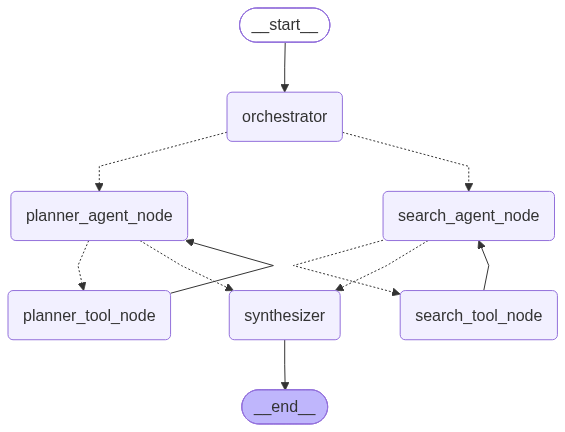

In [ ]:
# Show the agent
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### Test Multi-Agent Travel Planner

In [ ]:
# Regression test: duplicate router tasks must become one worker per destination
regression_state = {
    "user_query": "flight + hotel + itinerary",
    "messages": [],
    "tasks": [
        AgentTask(destination="search_agent_node", sub_query="find flights"),
        AgentTask(destination="search_agent_node", sub_query="find hotels"),
        AgentTask(destination="planner_agent_node", sub_query="plan itinerary"),
    ],
    "requires_synthesis": True,
    "agent_results": [],
    "final_answer": "",
    "search_messages": [],
    "planner_messages": [],
}

regression_sends = dispatch_to_agents(regression_state)
assert len(regression_sends) == 2, (
    f"Expected one worker per destination (2 total), got {len(regression_sends)}"
)
# Verify that grouping did not lose any instructions.
worker_inputs = {send.node: send.arg for send in regression_sends}
assert set(worker_inputs) == {"search_agent_node", "planner_agent_node"}

search_input = worker_inputs["search_agent_node"]["user_query"]
planner_input = worker_inputs["planner_agent_node"]["user_query"]
assert "find flights" in search_input
assert "find hotels" in search_input
assert "plan itinerary" in planner_input

print("PASS: 3 assignments became 2 workers; all instructions preserved")
print("Search Agent input:", search_input)
print("Planner Agent input:", planner_input)

PASS: 3 assignments became 2 workers; all instructions preserved
Search Agent input: - find flights

- find hotels
Planner Agent input: - plan itinerary


In [ ]:
agent = build_parallel_travel_agent()

config = {
    "configurable": {
        "thread_id": "samwel-clean-1"
    }
}

In [ ]:
result = agent.invoke({
        "user_query": "Plan a 5-day trip to Paris and find me flights from JFK to LHR for 1 adult only on 21 Jan 2026 (one way trip) & also let me know hotels for myself only (adult) from my lading to LHR to next day",
        "messages": []
    })

In [ ]:
result

{'messages': [AIMessage(content="# Trip Planning to Paris: Flights, Hotels, and Itinerary\n\n## Flights from JFK to LHR\nUnfortunately, there are currently no available flights from New York (JFK) to London Heathrow (LHR) on January 21, 2026. This may be due to the early booking window or specific airline schedules. **Consider checking back closer to your travel date or exploring alternative airports or dates.** \n\n## Hotels in London\nSimilarly, there are no hotel options available in London for the night of January 21, 2026. **If your plans are flexible, consider adjusting your travel dates or looking for accommodations in nearby areas.** \n\n## Suggested Itinerary for Paris\nWhile specific flights and hotels in London are not available, here’s a suggested 5-day itinerary for your stay in Paris:\n\n### Day 1: Arrival in Paris\n- **Check-in**: Choose a hotel in central Paris (e.g., Le Marais, Saint-Germain-des-Prés).\n- **Evening**: Stroll along the Seine and enjoy dinner at a local 

In [ ]:
# Print everything step by step
print("=" * 60)
print("USER QUERY:")
print(result["user_query"])

print("\n" + "=" * 60)
print("TASKS DISPATCHED:")
for task in result.get("tasks", []):
    print(f"  • {task.destination}: {task.sub_query}")

print("\n" + "=" * 60)
print("AGENT RESULTS:")
for r in result.get("agent_results", []):
    print(f"\n[{r['agent'].upper()}]")
    print("-" * 40)
    print(r["result"][:50000] + "..." if len(r["result"]) > 500 else r["result"])

print("\n" + "=" * 60)
print("FINAL SYNTHESIZED RESPONSE:")
print("=" * 60)
print(result["final_answer"])

USER QUERY:
Plan a 5-day trip to Paris and find me flights from JFK to LHR for 1 adult only on 21 Jan 2026 (one way trip) & also let me know hotels for myself only (adult) from my lading to LHR to next day

TASKS DISPATCHED:
  • search_agent_node: Find one-way flights from JFK to LHR for 1 adult on 21 Jan 2026.
  • search_agent_node: Find hotels in London for 1 adult for 1 night after arriving from JFK.
  • planner_agent_node: Plan a 5-day itinerary for Paris.

AGENT RESULTS:

[PLANNER_AGENT]
----------------------------------------
To create a tailored 5-day itinerary for Paris, I need to know a bit more about your preferences. Could you please provide the following details?

1. **Travel Dates**: When are you planning to visit?
2. **Interests**: Are you more interested in art, history, food, shopping, or outdoor activities?
3. **Travel Style**: Do you prefer a relaxed pace or a packed schedule?
4. **Accommodation**: Do you have a specific area in Paris where you would like to stay?
5.

# **Add Persistence**

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver # stores
from langchain_core.runnables import RunnableConfig #thread id

In [ ]:
def build_parallel_travel_agent():
    """Build the graph with parallel execution support."""

    builder = StateGraph(TravelPlannerState)

    # Add nodes
    builder.add_node("orchestrator", classify_query_parallel)
    builder.add_node("search_agent_node", search_agent_node)
    builder.add_node("planner_agent_node", planner_agent_node)
    builder.add_node("search_tool_node", search_tool_node)
    builder.add_node("planner_tool_node", planner_tool_node)
    builder.add_node("synthesizer", synthesizer_node)

    # Connect edges
    builder.add_edge(START, "orchestrator")

    # Router dispatches to agents via Send API (parallel execution)
    builder.add_conditional_edges(
        "orchestrator",
        dispatch_to_agents,
        ["search_agent_node", "planner_agent_node"]
    )

    # Search agent tool loop
    builder.add_conditional_edges(
        "search_agent_node",
        should_continue_for_searchAgent,
        ["search_tool_node", "synthesizer"]  # Go to synthesizer instead of END
    )
    builder.add_edge("search_tool_node", "search_agent_node")

    # Planner agent tool loop
    builder.add_conditional_edges(
        "planner_agent_node",
        should_continue_for_plannerAgent,
        ["planner_tool_node", "synthesizer"]  # Go to synthesizer instead of END
    )
    builder.add_edge("planner_tool_node", "planner_agent_node")

    # End after synthesis
    builder.add_edge("synthesizer", END)

    # Built-in Persistence
    checkpointer = InMemorySaver() # SHORT TERM MEMORY

    return builder.compile(checkpointer=checkpointer)

In [ ]:
# Compile the agent
agent = build_parallel_travel_agent()

In [ ]:
config_samwel = {"configurable": {"thread_id": "samwel"}} #uuid
config_arun = {"configurable": {"thread_id": "arun"}} #uuid
config_prasad = {"configurable": {"thread_id": "prasad"}}
config_sree = {"configurable": {"thread_id": "sree"}}

In [ ]:
result = agent.invoke(
    {
        "user_query": "What is the best time to visit Zanzibar?",
        "messages": [],
        "tasks": [],
        "requires_synthesis": False,
        "agent_results": [],
        "final_answer": "",
        "search_messages": [],
        "planner_messages": [],
    },
    config=config_samwel #samwel's
)

print(result['final_answer'])

### Best Time to Visit Zanzibar

Zanzibar has a tropical climate with two main seasons: a dry season and a wet season. Here’s a breakdown of the best times to visit based on weather conditions and activities:

#### **Dry Season (Best Time to Visit)**
- **Months:** June to October
- **Weather:** Sunny, low humidity, comfortable temperatures (25-30°C or 77-86°F)
- **Activities:** Ideal for beach activities, diving, snorkeling, and safari combinations.
- **Crowds:** High, especially in July and August.
- **Costs:** Higher due to peak tourist season.

#### **Shoulder Season**
- **Months:** November to early December
- **Weather:** Warm with light, short rains; temperatures remain pleasant.
- **Activities:** Good for sightseeing and local markets.
- **Crowds:** Moderate, making it a good time for budget travelers.
- **Costs:** Mid-range, with some deals available.

#### **Wet Season (Low Season)**
- **Months:** March to May (long rains) and November (short rains)
- **Weather:** High humidit

In [ ]:
result = agent.invoke(
    {
        "user_query": "Major historical sites there (must visit kind of)",
        "messages": [],
        "tasks": [],
        "requires_synthesis": False,
        "agent_results": [],
        "final_answer": "",
        "search_messages": [],
        "planner_messages": [],
    },
    config=config_samwel
)

print(result['final_answer'])

### Best Time to Visit Zanzibar

Zanzibar has a tropical climate with two main seasons: a dry season and a wet season. Here’s a breakdown of the best times to visit based on weather conditions and activities:

#### **Dry Season (Best Time to Visit)**
- **Months:** June to October
- **Weather:** Sunny, low humidity, comfortable temperatures (25-30°C or 77-86°F)
- **Activities:** Ideal for beach activities, diving, snorkeling, and safari combinations.
- **Crowds:** High, especially in July and August.
- **Costs:** Higher due to peak tourist season.

#### **Shoulder Season**
- **Months:** November to early December
- **Weather:** Warm with light, short rains; temperatures remain pleasant.
- **Activities:** Good for sightseeing and local markets.
- **Crowds:** Moderate, making it a good time for budget travelers.
- **Costs:** Mid-range, with some deals available.

#### **Wet Season (Low Season)**
- **Months:** March to May (long rains) and November (short rains)
- **Weather:** High humidit

In [ ]:
result = agent.invoke(
    {
        "user_query": "What all cities I can cover along with this tour (in nearby which should not take more than 2-3 days extra)",
        "messages": [],
        "tasks": [],
        "requires_synthesis": False,
        "agent_results": [],
        "final_answer": "",
        "search_messages": [],
        "planner_messages": [],
    },
    config=config_prasad # no history
)

print(result['final_answer'])

To provide you with the best suggestions for nearby cities that can be covered in a short tour, I need to know your starting city or region. Could you please specify where you are located or the city you have in mind for your tour?
